# Geospatial Deep Learning Pipeline 🌎​👾​

---

This notebook provides a step-by-step workflow to validate an object detection model using geospatial data. Specifically, it covers the following steps:

- ✂️​ **Create a labeled dataset from an orthomosaic**, ready to be processed by a detection model. The orthomosaic is split into fixed-size tiles.

- 🪄 **Run a detection model** to locate objects of interest (in this case, plants) within each tile.

- 🩹 **Merge tile-based predictions** to reconstruct a spatially consistent detection map that can be visualized on top of the original orthomosaic.

- 🧮 **Compute evaluation metrics** to assess the performance of the detection model.

Many of these steps rely on the package [**geodataset**](https://github.com/hugobaudchon/geodataset) 🌳. I originally implemented much of this functionality from scratch, but the solution provided by *geodataset* is really neat. Just in case, my original implementation is preserved in the `archive` folder of this repository.

---

## ✂️ Create and visualize the dataset 👁️


In this step, we **take an orthomosaic and its corresponding annotations and divide them into fixed-size tiles**. This produces a dataset ready for training, validation, or model inference.  
In this example, the dataset is used for **validation**, but `geodataset` provides many additional functionalities worth exploring.

For this step, we need two files:

* **Raster file**: the orthomosaic. I export it as a *rendered image*, which I find to be lighter and less prone to errors.
* **Labels**: the annotations. I created them directly in QGIS using **bounding boxes**, although `geodataset` also supports segmentation, export them as a **GPKG** and working in meters is generally easier.

The `geodataset` library also supports creating datasets without labels, which is useful when preparing data for inference on new, unseen areas.

---

No AOIs provided, all tiles will be kept in the DEFAULT_AOI_NAME AOI.
Reading raster...
Rescaling the raster with x_scale_factor=1.0207719986915276 and y_scale_factor=1.0277488727020465 to match ground_resolution=0.0136...
Expected raster size in memory: 0.07 GB.
Loading raster in memory (while resampling to scale_factor/ground_resolution)...


/home/paula/miniconda3/envs/mapenv/lib/python3.14/site-packages/pyogrio/geopandas.py:382: UserWarning: More than one layer found in 'rosettes_gsd_1cm_boxes.gpkg': '19_dic_2024_1cm_etiquetas' (default), 'rosettes_gsd_1cm_boxes'. Specify layer parameter to avoid this warning.
  result = read_func(


Raster size:  (2963, 6241)
Desired tile size:  512
Creating tiles and finding their associated labels...


Processing rows: 100%|██████████| 7/7 [00:00<00:00, 33.98it/s]


Finding the labels associated to each tile...
Assigning the tiles to the aois...
Final AOI 'all' saved to mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/rosettes_gsd_1cm_mosaic_aoi_gr0p0136_all.gpkg.
Finding the labels associated to each tile...
Saving the tiles and COCO json files...


Saving tiles for AOI 'all': 100%|██████████| 98/98 [00:02<00:00, 47.78it/s]


Verifying COCO file integrity...
Saved COCO dataset to mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/rosettes_gsd_1cm_mosaic_coco_gr0p0136_all.json.


{'all': PosixPath('mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/rosettes_gsd_1cm_mosaic_coco_gr0p0136_all.json')}

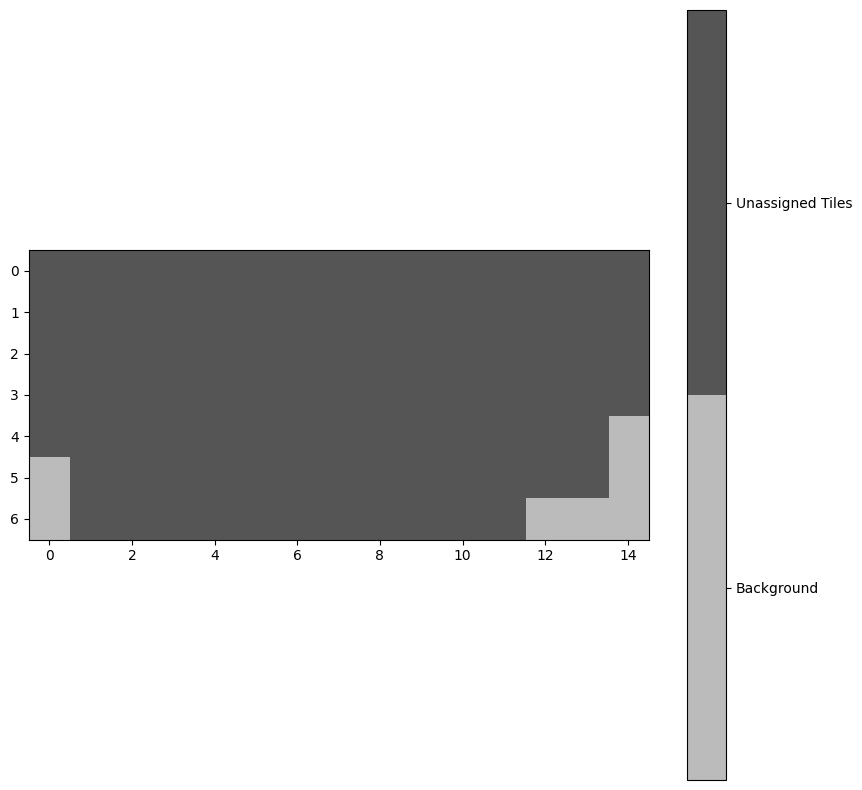

In [193]:
from pathlib import Path
from geodataset.tilerize import LabeledRasterTilerizer

tilerizer = LabeledRasterTilerizer(
    raster_path='./mosaics_val/rosettes_gsd_1cm/rosettes_gsd_1cm_mosaic.tif',
    labels_path='./mosaics_val/rosettes_gsd_1cm/rosettes_gsd_1cm_boxes.gpkg',
    output_path='./mosaics_val/rosettes_gsd_1cm/dataset',
    tile_size=512,
    tile_overlap=0.2,
    labels_gdf=None,                                 # optional (useful if you have the gdf already loaded in memory)
    ground_resolution=0.0136,                        # optional, scale_factor must be None if used.
    use_rle_for_labels=False,                        # optional
    min_intersection_ratio=0.6,                      # optional
    ignore_tiles_without_labels=False,               # optional
    ignore_black_white_alpha_tiles_threshold=0.8,    # optional
    coco_categories_list=[{"id": 0, "name": "plant", "supercategory": "object"}]  # optional
)

tilerizer.generate_coco_dataset()

We created the dataset now lets visualize it!

In [ ]:
# Lets checkout the dataset
from pathlib import Path
from geodataset.dataset import DetectionLabeledRasterCocoDataset

# Labeled Detection Dataset
detection_train_ds = DetectionLabeledRasterCocoDataset(
    root_path=['./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic'],
    fold="all",
    transform=None
)

Found 77 tiles and 959 labels for fold all.


In [196]:
# there is a small error in the detection labeled raster coco
# the unlabeled images not appear in the coco dataset...
import json
from pathlib import Path
import rasterio

def add_missing_images_to_coco(
    coco_json_path,
    tiles_dir,
    output_json_path=None,
    exts=(".tif", ".tiff", ".png")
):
    if output_json_path is None:
        output_json_path = coco_json_path

    with open(coco_json_path, "r") as f:
        coco = json.load(f)

    # Existing filenames in GT
    existing_files = {img["file_name"] for img in coco["images"]}

    # Existing max image id
    max_img_id = max(img["id"] for img in coco["images"]) if coco["images"] else 0

    print(f"Existing images in COCO GT: {len(existing_files)}")

    tiles_dir = Path(tiles_dir)
    added = 0

    for img_path in sorted(tiles_dir.iterdir()):
        if img_path.suffix.lower() not in exts:
            continue

        fname = img_path.name
        if fname in existing_files:
            continue

        # Read image size safely
        with rasterio.open(img_path) as src:
            width = src.width
            height = src.height

        max_img_id += 1
        coco["images"].append({
            "id": max_img_id,
            "file_name": fname,
            "width": width,
            "height": height
        })

        added += 1

    with open(output_json_path, "w") as f:
        json.dump(coco, f, indent=2)

    print(f"Added {added} missing images to COCO GT.")
    print(f"Saved fixed GT to: {output_json_path}")


add_missing_images_to_coco(
    "./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/rosettes_gsd_1cm_mosaic_coco_gr0p0136_all.json",
    "./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/tiles/all",
    output_json_path=None,
    exts=(".tif", ".tiff", ".png")
)

Existing images in COCO GT: 77
Added 21 missing images to COCO GT.
Saved fixed GT to: ./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/rosettes_gsd_1cm_mosaic_coco_gr0p0136_all.json


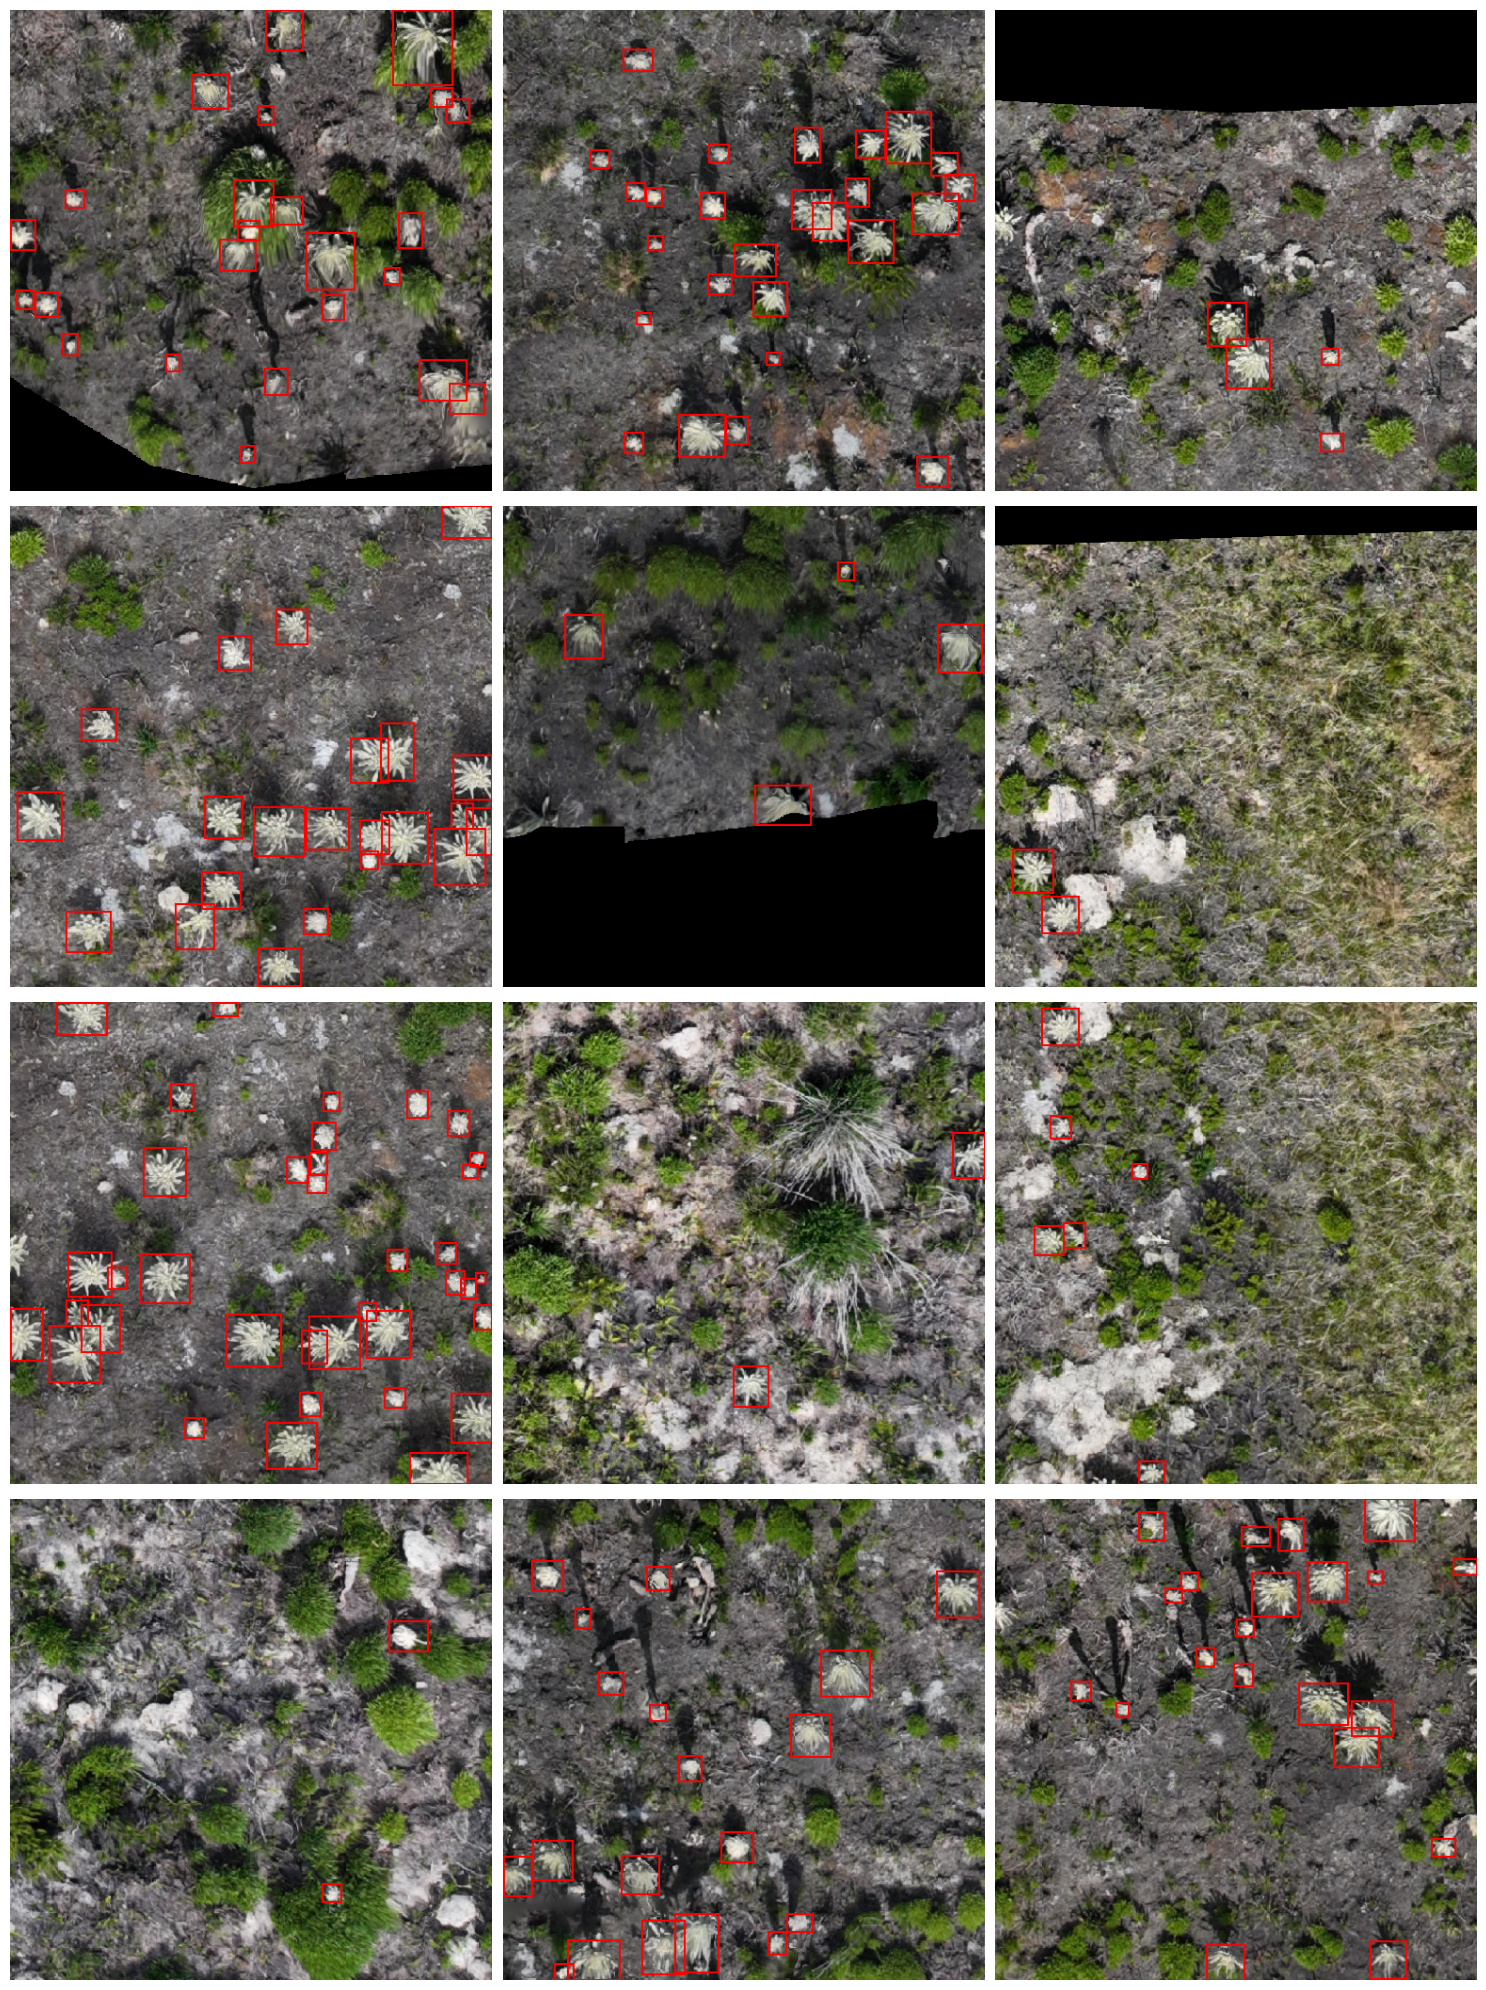

In [107]:
from matplotlib import pyplot as plt
import numpy as np
import torch
from torchvision.utils import draw_bounding_boxes
import random

# how many samples
N = 12
rows, cols = 4, 3

# random indices
indices = random.sample(range(len(detection_train_ds)), N)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
axes = axes.flatten()

for ax, idx in zip(axes, indices):
    tile = detection_train_ds.__getitem__(idx)

    image = tile[0]

    # numpy (H, W, C) → torch (C, H, W)
    image_t = torch.from_numpy(image)

    # ensure uint8
    if image_t.dtype != torch.uint8:
        image_t = (image_t * 255).to(torch.uint8)

    boxes = torch.as_tensor(tile[1]["boxes"], dtype=torch.float32)

    img_with_boxes = draw_bounding_boxes(
        image_t, boxes, colors="red", width=2
    )

    ax.imshow(img_with_boxes.permute(1, 2, 0))
    ax.axis("off")



plt.tight_layout()
plt.show()

Some statistics about our dataset that might be interesting

In [173]:
import json
from collections import defaultdict

coco_path = "./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/rosettes_gsd_1cm_mosaic_coco_gr0p0136_all.json"

with open(coco_path, "r") as f:
    coco = json.load(f)

# Basic counts
num_images = len(coco["images"])
num_objects = len(coco["annotations"])

# Count annotations per image
ann_per_image = defaultdict(int)
for ann in coco["annotations"]:
    ann_per_image[ann["image_id"]] += 1

# Blank images = images with no annotations
image_ids = {img["id"] for img in coco["images"]}
blank_images = image_ids - ann_per_image.keys()
num_blank_images = len(blank_images)

# Average objects per image
avg_objects_per_image = num_objects / num_images if num_images > 0 else 0

print(f"Number of images: {num_images}")
print(f"Total number of objects: {num_objects}")
print(f"Average objects per image: {avg_objects_per_image:.2f}")
print(f"Number of blank images: {num_blank_images}")


Number of images: 98
Total number of objects: 959
Average objects per image: 9.79
Number of blank images: 21


## 🪄 Predict! Let’s find plants using a detection model 🔍

Now let’s **run a detection model on our dataset.**

Since here we will be using a model from **Ultralytics**, the input images need to be in **PNG** format. For that reason, we convert the tiles from **.tif** to **png**.  
This step is **optional** and depends on the model and framework you are using.

In [ ]:
from pathlib import Path
import rasterio
import numpy as np
import cv2

# input / output dirs
tiff_dir = Path("./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/tiles/all")
png_dir = Path("./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/tiles_png")

png_dir.mkdir(parents=True, exist_ok=True)

for tif_path in tiff_dir.glob("*.tif"):
    print(f"Converting {tif_path.name}...")
    with rasterio.open(tif_path) as src:
        # read RGB bands (change if needed)
        img = src.read([1, 2, 3])   # (3, H, W)

    # CHW → HWC
    img = np.moveaxis(img, 0, -1)

    # convert to uint8 if needed
    if img.dtype != np.uint8:
        img = np.clip(img, 0, 255)
        img = img.astype(np.uint8)

    # RGB → BGR for OpenCV
    img = img[:, :, ::-1]
    out_path = png_dir / f"{tif_path.stem}.png"
    cv2.imwrite(str(out_path), img)

print("Done converting TIFF → PNG")


Now we run our model on the png images and get the predictions

In [174]:
# Lets predict with this dataset :3
import rasterio
import numpy as np
from ultralytics import YOLO

model_weights = "./models/yolov11_best.pt"
images_directory = "./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/tiles_png"

model = YOLO(model_weights)
results = model.predict(source=images_directory, imgsz=512,stream = True)

Again, since we are using a model from ultralytics we want to save the predictions in the coco format, so that the geodataset library can help us post-process them

In [ ]:
import json
from pathlib import Path

def yolo_results_to_coco(results, dataset_json, output_json):
    coco = {
        "images": [],
        "annotations": [],
        "categories": []
    }

    with open(dataset_json, "r") as f:
        dataset = json.load(f)
        coco["categories"] = dataset["categories"]

    ann_id = 1


    for r in results:
        # image info
        h, w = r.orig_shape
        image_name = Path(r.path).name
        # find match with coco dataset image id
        matches = [
            img["id"] for img in dataset["images"]
            if img["file_name"] == image_name.replace(".png", ".tif")
        ]

        # set image id as the one found
        img_id = matches[0] if matches else dataset["images"][-1]["id"] + 1 if dataset["images"] else 1
        print(img_id)

        coco["images"].append({
            "id": img_id,
            "file_name": image_name.replace(".png", ".tif"),
            "width": w,
            "height": h
        })

        if r.boxes is not None:
            boxes = r.boxes.xyxy.cpu().numpy()
            scores = r.boxes.conf.cpu().numpy()
            classes = r.boxes.cls.cpu().numpy().astype(int)

            for box, score, cls in zip(boxes, scores, classes):
                x1, y1, x2, y2 = box
                bw = x2 - x1
                bh = y2 - y1
                # -------------------------
                # Polygon segmentation
                # -------------------------
                segmentation = [[
                    float(x1), float(y1),
                    float(x2), float(y1),
                    float(x2), float(y2),
                    float(x1), float(y2)
                ]]

                coco["annotations"].append({
                    "id": ann_id,
                    "image_id": img_id,
                    "category_id": int(cls),
                    "bbox": [float(x1), float(y1), float(bw), float(bh)],
                    "area": float(bw * bh),
                    "iscrowd": 0,
                    "score": float(score),
                    "is_rle_format": False,
                    "segmentation": segmentation,
                    "other_attributes": {}
                })
                ann_id += 1

        img_id += 1

    with open(output_json, "w") as f:
        json.dump(coco, f, indent=2)



    print(f"Saved COCO predictions to: {output_json}")



yolo_results_to_coco(results, "./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/rosettes_gsd_1cm_mosaic_coco_gr0p0136_all.json", "./mosaics_val/rosettes_gsd_1cm/predictions/yolo_predictions_coco.json")


## 🩹 Use the aggregator to join predictions into a GeoPackage

The model predictions are generated **per tile**, but to visualize them properly we need to merge them back into a single geospatial layer.

In this step:
- Convert tile-based predictions back to **geospatial coordinates**
- Aggregate all detections into a unified layer
- Export the results as a **GeoPackage (GPKG)** so they can be easily visualized on top of the original orthomosaic (e.g., in QGIS)

Sounds like a lot but geodataset handles this, we just need to have our coco files in order

In [177]:
# Now that we have our coco prediction lets use the aggregator to get the predictions as gpkg files
from shapely.geometry import box, Polygon
from geodataset.aggregator import Aggregator

# aggregating detection bounding boxes from a coco file on the disk:
aggregator = Aggregator.from_coco(
    polygon_type="bbox",
    output_path='./mosaics_val/rosettes_gsd_1cm/predictions/predictions_yolov11.gpkg',
    tiles_folder_path='./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/tiles/all',
    coco_json_path='./mosaics_val/rosettes_gsd_1cm/predictions/yolo_predictions_coco.json',
    scores_names=['score'],
    score_threshold=0.4,
    nms_threshold=0.2,
    nms_algorithm='iou',
    edge_band_buffer_percentage=0.0
)

Reverting tiles polygons to CRS coordinates: 100%|██████████| 84/84 [00:01<00:00, 71.93it/s]


Removed 154 out of 1225 polygons as they were under the score_threshold=0.4.


Applying NMS-iou algorithm: 100%|██████████| 1071/1071 [00:00<00:00, 1478.00it/s]


Removed 399 out of 1071 polygons by applying the Non-Maximum Suppression-iou algorithm.
Saved 672 polygons in file 'mosaics_val/rosettes_gsd_1cm/predictions/predictions_yolov11.gpkg'.


## 🧮 Metric computation

Finally, to evaluate how well the model performed, we compute metrics at **two scales**.

### 1. Calculate metrics at the orthomosaic level

Since we are interested in the **spatial performance of the model across the entire area of interest**. Metrics are computed using the **merged, georeferenced predictions**, allowing us to really assess how many objects were detected in our area of interest.

We compute the following metrics:

- **Precision**: proportion of detected objects that were correctly identified. (True positives) / (Ground truth)
- **Recall**: proportion of ground-truth objects that are successfully detected  (True positives) / All detected objects
- **F1-score**: harmonic mean of precision and recall  


First some necesary functions to compute detection metrics at the raster level

In [178]:
import math
import numpy as np
from shapely.geometry import Polygon


"""
Calculate Intersection over Union (IoU) between two bounding boxes.
box1, box2: dictionaries with keys ['xmin', 'ymin', 'xmax', 'ymax']
"""
def calculate_iou(box1, box2):

    intersection_area = box1.geometry.intersection(box2.geometry).area

    # Compute areas of both boxes
    area_box1 = box1.geometry.area
    area_box2 = box2.geometry.area

    # Compute union area
    union_area = area_box1 + area_box2 - intersection_area

    # Return IoU
    if union_area == 0:
        return 0
    return intersection_area / union_area


def compute_labels_fast(gt_df, pred_df, iou_threshold=0.5, conf_threshold=0.5, confidence_column = "confidence"):
    predictions = pred_df[pred_df[confidence_column] >= conf_threshold].sort_values(by=confidence_column, ascending=False)

    gt_labels = []
    pred_labels = []

    matched_gt = set()
    matched_pred = set()
    
    for i, pred in predictions.iterrows():
        match_found = False
        for j, gt in gt_df.iterrows():
            if j in matched_gt:
                continue
            iou = calculate_iou(pred, gt)
            if iou >= iou_threshold:
                pred_labels.append(1)  # TP
                gt_labels.append(1)
                matched_gt.add(j)
                matched_pred.add(i)
                match_found = True
                break
        if not match_found:
            pred_labels.append(1)  # FP
            gt_labels.append(0)

    # False Negatives = unmatched GTs
    unmatched_gt = [j for j in gt_df.index if j not in matched_gt]
    num_fn = len(unmatched_gt)

    # Add FN for each unmatched ground truth
    pred_labels.extend([0] * num_fn)
    gt_labels.extend([1] * num_fn)

    return gt_labels, pred_labels

In [180]:
pred_path = "./mosaics_val/rosettes_gsd_1cm/predictions/predictions_yolov11_mod.gpkg"
gt_path = "./mosaics_val/rosettes_gsd_1cm/rosettes_gsd_1cm_boxes.gpkg"

import geopandas as gpd

bounding_boxes = gpd.read_file(gt_path, layer="rosettes_gsd_1cm_boxes")
pred_boxes = gpd.read_file(pred_path)

# make sure gt and predictions geometries are in the same CRS
# I find that changing the crs in QGIS works best
print(bounding_boxes.crs)
print(pred_boxes.crs)

EPSG:32618
EPSG:32618


In [181]:
gt_labels, pred_labels = compute_labels_fast(bounding_boxes, pred_boxes, iou_threshold=0.5, conf_threshold=0.5, confidence_column="score")

Precision: 0.9091
Recall: 0.8837
F1 Score: 0.8962


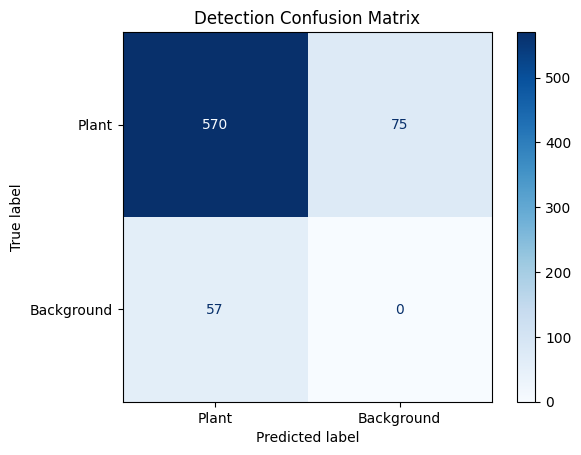

In [182]:
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(gt_labels, pred_labels, labels=[1, 0])

# Display and save the confusion matrix as an image
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Plant", "Background"])
disp.plot(cmap=plt.cm.Blues)
# Save the plot
plt.title("Detection Confusion Matrix")

precision = precision_score(gt_labels, pred_labels, zero_division=1)
recall = recall_score(gt_labels, pred_labels, zero_division=1)
f1 = f1_score(gt_labels, pred_labels, zero_division=1)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")


### 2. Calculate mAP

We evaluate the model using a standard **object detection metric**, computed directly on the tiled dataset.

**mean Average Precision (mAP)**: measures how well the model localizes and classifies objects across different Intersection over Union (IoU) thresholds.

To do this we will use the coco package.

In [197]:
import json
import os

pred_json_path= "./mosaics_val/rosettes_gsd_1cm/predictions/yolo_predictions_coco.json"
gt_json_path = "./mosaics_val/rosettes_gsd_1cm/dataset/rosettes_gsd_1cm_mosaic/rosettes_gsd_1cm_mosaic_coco_gr0p0136_all.json"

# make sure the imagaes in pred and gt json are the same, (geodata may just take into account images that have labels for the gt)

with open(pred_json_path, "r") as f:
    pred_coco = json.load(f)

pred_annotations = pred_coco["annotations"]   

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

coco_gt = COCO(gt_json_path)
coco_dt = coco_gt.loadRes(pred_annotations)
coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")  # or "segm"
coco_eval.evaluate()
coco_eval.accumulate()
coco_eval.summarize()


loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.44s).
Accumulating evaluation results...
DONE (t=0.02s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.586
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.912
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.709
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.534
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.639
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = -1.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.055
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.392
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet